<img src="https://bioinf.nl/~davelangers/hanze.png" align="right" />

# <span id="0">Casus *Dynamic Modelling (ODEs)*</span>

Inhoud:

* **<a href="#1">Doel</a>**

* **<a href="#2">Inspiratie</a>**

* **<a href="#3">Modellen</a>**

* **<a href="#4">Datasets</a>**

<a id="1" href="#0" style="text-align: right; display: block;">Terug naar boven</a>

### Doel

In deze casus ga je jezelf verdiepen in dynamische modellen op basis van differentiaalvergelijkingen, en hoe je numerieke methoden kan gebruiken om deze met behulp van de computer op te lossen en te optimaliseren. Je onderzoekt hoe dergelijke technieken gebruikt kunnen worden om in het bijzonder beschrijvend de groei van tumoren te modelleren.

Het eindproduct van deze casus bestaat uit de volgende zaken in samenhang:

<div class="alert alert-block alert-warning">

* een eigen python-module of -package dat classes en/of functies biedt om meerdere gangbare tumorgroeimodellen te evalueren en te fitten aan beschikbare data van de gebruiker en om op een onderbouwde manier een conclusie te trekken omtrent het best passende model;

* een uitgebreid markdown readme document dat niet alleen de technische specificaties en afhankelijkheden van je module/package benoemt, maar dat aan de gebruiker ook bondige achtergrondinformatie geeft over de gebruikte modellen en technieken (incl. referenties);

* een jupyter-notebook dat een use-case illustreert waarbij je module/package wordt toegepast op realistische datasets van beperkte omvang en waarin door middel van inzichtelijke visualisaties begrip van de data en de modellen wordt getoond.

</div>

Je module dient meerdere voorgedefinieerde tumorgroeimodellen te bevatten in de vorm van differentiaalvergelijkingen die numeriek geïntegreerd en geoptimaliseerd kunnen worden gebruikmakend van verschillende methoden. Je mag hierbij gebruik maken van wetenschappelijke modules zoals `scipy`, maar je module dient op zijn minst ook één eigen implementatie van een ODE-solver en één eigen implementatie van een optimalisatie-methode te omvatten. In het notebook dien je je module op een zinvolle manier toe te passen op meerdere voorbeeld-datasets, hetzij verkregen uit de literatuur hetzij gesimuleerde data.

Zorg voor een werkbare taakverdeling, maar zorg wel dat eenieder bijdraagt aan inhoudelijke delen van het eindproduct op het gebied van zowel code als documentatie. Merk op dat het eindproduct niet zozeer het *doel* is van deze casus: het is het *middel* waarmee je kan laten zien dat je jezelf de achtergronden van modelleren middels differentiaalvergelijkingen eigen hebt gemaakt.

Deze casus bestaat *niet* uit kleine deelopdrachten. Je bepaalt zelf hoe je invulling gaat geven aan de bovenstaande doelen. Wel wordt in vier lessen in de vorm van "workshops" aandacht besteed aan de volgende onderwerpen:

1. differentiaalvergelijkingen
2. ODE-solvers
3. niet-lineaire regressie methoden
4. modelvergelijking met AIC en BIC criteria

Daarnaast volgen hieronder meer informatie en aanknopingspunten omtrent een aantal relevante onderwerpen.

<a id="2" href="#0" style="text-align: right; display: block;">Terug naar boven</a>

### Inspiratie

In 2023 publiceerde de student Kenneth Chan van Pine Crest School, Claremont McKenna College een kort paper in het *Journal of Student Research* (Volume 12, Issue 4) onder de titel "Treatment Optimization for Tumor Growth by Ordinary Differential Equations" [DOI: 10.47611/jsrhs.v12i4.5202](https://www.researchgate.net/publication/378286328_Treatment_Optimization_for_Tumor_Growth_by_Ordinary_Differential_Equations). In dit paper past de auteur meerdere verschillende modellen van tumorgroei toe op diverse bestaande datasets om zo het best passende model te identificeren. Daarnaast bekijkt hij onder vereenvoudigde aannamen het effect van kankertherapie.

**ABSTRACT**

*Cancer is the second leading cause of death worldwide and with the disease having over 200 variations, it has not been cured yet despite being the priority of the medical field for decades. Due to the difficulty of human subject research, animal studies, e.g., mouse and Chinese hamster V79 tumors have been widely used to test the modeling of tumor growth due to their dynamic nature and ability to grow to high volumes within short periods of time. Mathematical models, including ordinary differential equations (ODEs), have been utilized to model tumor growth and study treatment of cancer. With most current models being selected only for mathematical convenience, recent studies have been focusing on determining the optimal treatment schedule for the most popular existing treatments of chemotherapy and radiation therapy. In this paper, three of the most established ODE models: the Gompertz, Von Bertalanffy, and logistic models are utilized to analyze which model most accurately fits existing tumor growth data for the Chinese Hamster V79 fibroblast tumor, various forms of immunodeficient mice tumors, and glioblastoma based on the minimization of the normalized mean squared error (NMSE). Next, the ODEs themselves were modified to simulate the growth of the tumors when exposed to treatment and determined which treatment schedule produced the lowest final volume of the tumors. The results of this research identify the optimal treatment schedules based on data from all three ODE models and also determine the ODE models that produce curves that most precisely fit the datasets.*

Maak je de inhoud van dit korte paper goed eigen: met je module/package zou je iets soortgelijks moeten kunnen doen als in deze publicatie wordt gedaan (wellicht met uitzondering van het simuleren van een behandeling).

<a id="3" href="#0" style="text-align: right; display: block;">Terug naar boven</a>

### Modellen

De groei van tumoren kan worden beschreven door middel van differentiaalvergelijkingen: de verandering in het volume ($V$) van een tumor over de tijd ($t$) is een functie van het huidige volume van de tumor.

$$
\frac{\text{d}V}{\text{d}t} = f(V)
$$

Hoewel het volume varieert over de tijd, $V(t)$, hangt de functie $f$ zelf niet expliciet af van de tijd. Het model is *tijd-invariant* (d.w.z. het gedrag van de groei van een tumor hangt niet af van het moment waarop hij begonnen is te groeien). Afhankelijk van de keuze en aannames rond de functie $f$ kunnen verschillende modellen worden verkregen. In de literatuur worden bijvoorbeelde de onderstaande modellen veel aangetroffen.

* **Lineaire groei**

$$
\frac{\text{d}V}{\text{d}t} = c
$$

* **Exponentieel toenemende groei**

$$
\frac{\text{d}V}{\text{d}t} = c \cdot V
$$

* **Mendelsohn groei**

$$
\frac{\text{d}V}{\text{d}t} = c \cdot V^d
$$

* **Exponentieel afvlakkende groei**

$$
\frac{\text{d}V}{\text{d}t} = c \cdot \left( V_\max - V \right)
$$

* **Logistische groei**

$$
\frac{\text{d}V}{\text{d}t} = c \cdot V \cdot \left( V_\max - V \right)
$$

* **Montroll groei**

$$
\frac{\text{d}V}{\text{d}t} = c \cdot V \cdot \left( V_\max^d - V^d \right)
$$

* **Allee effect groei**

$$
\frac{\text{d}V}{\text{d}t} = c \cdot \left( V - V_\min \right) \cdot \left( V_\max - V \right)
$$

* **Lineair gelimiteerde groei**

$$
\frac{\text{d}V}{\text{d}t} = c \cdot \frac{V}{V + d}
$$

* **Oppervlakte-gelimiteerde groei**

$$
\frac{\text{d}V}{\text{d}t} = c \cdot \frac{V}{\left( V + d \right)^\frac{1}{3}}
$$

* **Von Bertalanffy groei**

$$
\frac{\text{d}V}{\text{d}t} = c \cdot V^\frac{2}{3} - d \cdot V
$$

* **Gompertz groei**

$$
\frac{\text{d}V}{\text{d}t} = c \cdot V \cdot \ln \left( \frac{V_\max}{V} \right)
$$

De variabelen $c$, $d$, $V_\min$ en $V_\max$ representeren parameters waarvan de juiste waarde bepaald kan worden aan de hand van beschikbare data. De modellen lopen uiteen in complexiteit en realisme. Sommige van deze modellen kennen exacte wiskundige oplossingen. Ze kunnen allemaal door middel van numerieke methoden worden opgelost. Desalniettemin gedragen sommige modellen zich numeriek "netter" dan sommige andere. In deze casus gebruiken we daarom de bovenstaande formuleringen in termen van differentiaalvergelijkingen.

De aanname dat de groei van een tumor alleen afhangt van zijn volume en niet van de verdere interne "toestand" van de tumor is een grote beperking. Modellen kunnen worden uitgebreid om een betere beschrijving te geven van de biologische realiteit. Hierbij kunnen bijvoorbeeld verschillende compartimenten worden onderscheiden, of toevalseffecten worden ingebouwd. De invloed van angiogenese, van het immuunsysteem, of van een medische behandeling zoals chemo- of radiotherapie kan hierin worden verwerkt. Een betrekkelijk recente publicatie met een overzicht van veel gangbare modellen is [A. Yin et al., 2019](https://doi.org/10.1002/psp4.12450) ("A Review of Mathematical Models for Tumor Dynamics and Treatment Resistance Evolution of Solid Tumors", *CPT Pharmacometrics Syst. Pharmacol.* 8, 720–737). Het voert te ver om deze hier allemaal te noemen, maar je kunt een aantal hiervan bijvoorbeeld nader verkennen in je casus of in je Verdiepend Project.

<a id="4" href="#0" style="text-align: right; display: block;">Terug naar boven</a>

### Datasets

Met je module/package zou het mogelijk moeten zijn om eenvoudig modellen te fitten en plotten op datasets soortgelijk als hieronder (en meer).

In [6]:
import pandas as pd
from matplotlib import pyplot as plt

De onderstaande kleine dataset omtrent tumorgroei werd recent gepubliceerd door [S.S. Hassan & H.M. Al-Saedi, 2024](https://doi.org/10.1051/bioconf/20249700118) ("Comparative Study of Tumor Growth Based on Single Species Models", *BIO Web of Conferences* 97, 00118)

In [7]:
ts = [0, 13, 20, 32, 42, 55, 65, 75, 85, 88, 95, 98, 107, 115, 120]
Vs = [250, 255, 550, 575, 576, 800, 1050, 1250, 1750, 2000, 2550, 2750, 3000, 3500, 4000]

pd.DataFrame({'$t$': ts, '$V$': Vs}).T

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
$t$,0,13,20,32,42,55,65,75,85,88,95,98,107,115,120
$V$,250,255,550,575,576,800,1050,1250,1750,2000,2550,2750,3000,3500,4000


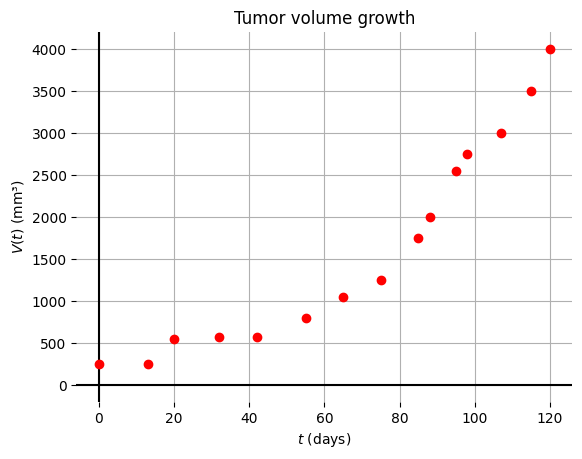

In [8]:
plt.axhline(0.0, color='k'); plt.axvline(0.0, color='k')
plt.plot(ts, Vs, 'or')
plt.title('Tumor volume growth'); plt.xlabel('$t$ (days)'); plt.ylabel('$V(t)$ (mm³)')
plt.grid(True); plt.box(False)
plt.show()

In de genoemde publicatie wordt deze data gefit met een aantal van de beschikbare modellen om het volgende resultaat te verkrijgen (zie Fig. 6 aldaar).

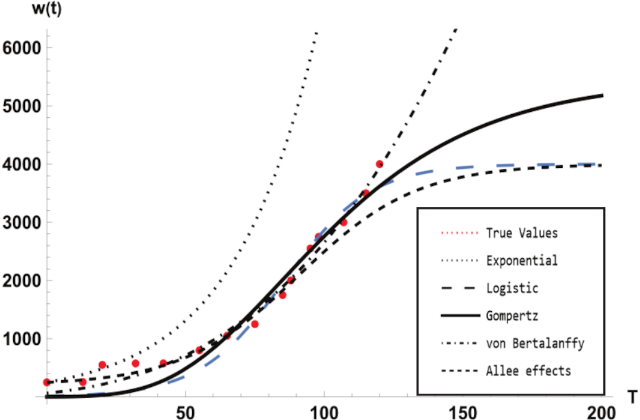

De onderstaande dataset is te vinden in [Rodrigues, 2024](https://doi.org/10.3390/math12081195) ("Using Physics-Informed Neural Networks (PINNs) for Tumor Cell Growth Modeling", *Mathematics* 12, 1195)

In [9]:
ts = [
     3.46,  4.58,  5.67,  6.64,  7.63,  8.41,  9.32, 10.27, 11.19,
    12.39, 13.42, 15.19, 16.24, 17.23, 18.18, 19.29, 21.23, 21.99,
    24.33, 25.58, 26.43, 27.44, 28.43, 30.49, 31.34, 32.34, 33.00,
    35.20, 36.34, 37.29, 38.50, 39.67, 41.37, 42.58, 45.39, 46.38,
    48.29, 49.24, 50.19, 51.14, 52.10, 54.00, 56.33, 57.33, 59.38,
]
Vs = [
    0.0158, 0.0264, 0.0326, 0.0445, 0.0646, 0.0933, 0.1454, 0.2183, 0.2842,
    0.4977, 0.6033, 0.8441, 1.2163, 1.4470, 2.3298, 2.5342, 3.0064, 3.4044,
    3.2046, 4.5241, 4.3459, 5.1374, 5.5376, 4.8946, 5.0660, 6.1494, 6.8548,
    5.9668, 6.6945, 6.6395, 6.8971, 7.2966, 7.2268, 6.8815, 8.0993, 7.2112,
    7.0694, 7.4971, 6.9974, 6.7219, 7.0523, 7.1095, 7.0694, 8.0562, 7.2268, 
]

pd.DataFrame({'$t$': ts, '$V$': Vs}).T

,0,1,2,3,4,5,6,7,8,9,...,35,36,37,38,39,40,41,42,43,44
$t$,3.4600,4.5800,5.6700,6.6400,7.6300,8.4100,9.3200,10.2700,11.1900,12.3900,...,46.3800,48.2900,49.2400,50.1900,51.1400,52.1000,54.0000,56.3300,57.3300,59.3800
$V$,0.0158,0.0264,0.0326,0.0445,0.0646,0.0933,0.1454,0.2183,0.2842,0.4977,...,7.2112,7.0694,7.4971,6.9974,6.7219,7.0523,7.1095,7.0694,8.0562,7.2268


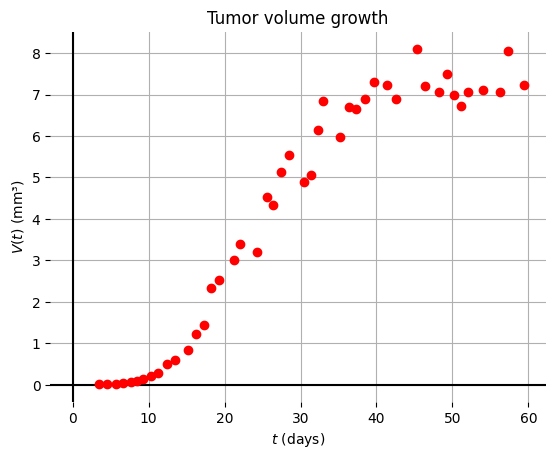

In [10]:
plt.axhline(0.0, color='k'); plt.axvline(0.0, color='k')
plt.plot(ts, Vs, 'or')
plt.title('Tumor volume growth'); plt.xlabel('$t$ (days)'); plt.ylabel('$V(t)$ (mm³)')
plt.grid(True); plt.box(False)
plt.show()

In de genoemde publicatie wordt deze data gefit met een Montroll model om het volgende resultaat te verkrijgen (zie Fig. 4 aldaar).

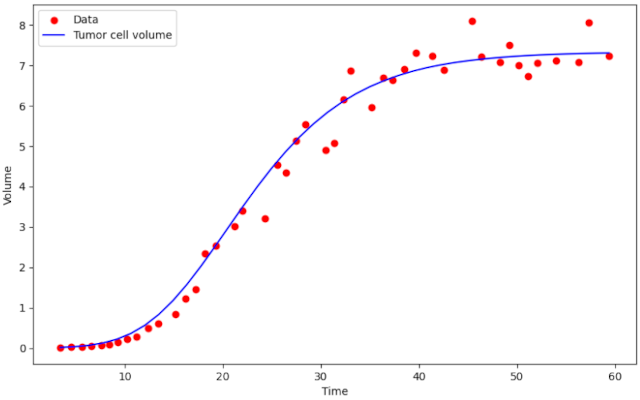

Ga ook zelf op zoek naar geschikte datasets in de literatuur, of genereer eventueel gesimuleerde data.

***

&copy; 2025 - Dave R.M. Langers <d.r.m.langers@pl.hanze.nl>